# Pour commencer

Dans ce notebook, nous allons présenter un premier point de départ pour commencer le projet.

Plan du notebook:
1. les classes de base
2. la classe `Account`
3. créer une stratégie
4. charger les données
4. le jeu
5. les tests
6. afficher les résultats

## Les classes de bases

Les classes de bases à utiliser dans ce projet sont les fichiers commençant par le nom `Base...`:
- `BaseClasses` : contenant les classes `Account`, `Game` et `IStrategy`
- `BaseLoader` : contenant la classe `Loader` permettant de charger les données depuis des fichiers, obtenu à partir de plusieurs sources web. Les fichiers chargés sont contenus dans le dossier `data`
- `BaseEvalGame`: contenant la classe `EvalGame`, permettant d'évaluer une stratégie sur une jeu de données, ou plusieurs jeux de données

La première chose à faire dans vos notebooks est donc de charger les classes de bases :


In [1]:
%run -i "BaseLoader.ipynb"
%run -i "BaseClasses.ipynb"
%run -i "BaseEvalGame.ipynb"

La seconde chose à faire est de bien comprendre comment fonctionne ces classes. Les fichiers `Base... - Test.ipynb` présentent des exemples d'utilisation de ces classes.

Nous allons ici refaire une passe sur ces classes, mais si vous voulez plus d'exemples, passez les précédents fichiers `... - Test.ipynb` en revue.

## Account

La classe `Account` permet de représenter le compte d'un utilisateur:
- à la construction, on définit le montant de cash que l'on compte investir
- la méthode `cashIn` permet d'ajouter du cash sur son compte
- les méthodes `invest` et `desinvest` permettent respectivement d'investir une partie de votre cash et de désinvestir une partie de vos sécurités mobilières
- les méthodes `investAll` et `desinvestAll` permettent respectivement d'investir **tout** votre cash et de désinvestir **toutes** vos sécurités mobilières
- les méthodes `getTheoricalValue` et `getTheoricalGain` permettent d'avoir la valeur de votre portefeuille à l'instant t et d'obtenir vos gains

Voici un exemple :

In [2]:
user = Account(1000)
unityPrice = 11.024

user.investAll(unityPrice)

print("1. Etat du compte de user:")
print(user)

user.cashIn(1000)
user.invest(500, unityPrice)

print("2. Etat du compte de user:")
print(user)

unityPrice = 11.512

user.desinvestAll(unityPrice)

print("3. Etat du compte de user:")
print(user)

print("Valeur:", user.getTheoricalValue(unityPrice))
print("Gain:", user.getTheoricalGain(unityPrice))


1. Etat du compte de user:
Cash courant: 0 & Security: 90.711175616836 & Cash investi: 1000
2. Etat du compte de user:
Cash courant: 500 & Security: 136.066763425254 & Cash investi: 2000
3. Etat du compte de user:
Cash courant: 2066.4005805515244 & Security: 0.0 & Cash investi: 2000
Valeur: 2066.4005805515244
Gain: 66.4005805515244


En pratique, vous n'allez pas utiliser la classe `Account`. Vous allez simplement renvoyer un ordre via votre classe `Strategy` qui sera appliqué sur votre `Account`.

## Strategy

Pour créer une classe `Strategy` il est nécessaire de regarder la classe `IStrategy` située dans le fichier `BaseClasses.ipynb`. Une stratégie est representée par:
- un constructeur prenant un nom et une variable indiquant si la stratégie est aléatoire ou non (si elle est aléatoire, il est nécessaire de réaliser les tests plusieurs dessus pour obtenir un gain moyen)
- une méthode `getAction(self, game, unityPrice, account, date, unityData=None, debug=False)` appelée en pratique par le jeu. Cette méthode prend en paramètre le jeu, le prix du jour, un `account`, la date du jour et des données en plus pouvant être utilisé pour sélectionner son action
- la méthode `getAction` doit retourner un couple `(action, montant)` où `montant` est soit un nombre de valeurs mobilières, soit un montant en euros.
- les différentes actions que vous pourrez retourner sont : 
```
    Game.STILL
    Game.INVEST
    Game.DESINVEST
    Game.INVEST_ALL
    Game.DESINVEST_ALL
    Game.CASH_IN
```

En pratique, voici comment créer votre propre `Strategy`:
1. créer une classe héritant de `IStrategy`
2. faire le constructeur en prenant le nom et le booléen indiquant si votre stratégie est aléatoire ou non
3. ajouter les données dont vous aurez besoin dans votre constructeur, qui pourront être utilisées dans la méthode `getAction` (avec `self.maData`)
4. implémenter la fonction `getAction`

Voici un exemple de stratégie d'un utilisateur choisissant tous les jours une action aléatoirement: soit ne rien faire, soit investir tout son cash, soit tout desinvestir, soit ajouter du cash sur son compte.

In [11]:
import random

class MyStrategy(IStrategy):

    def __init__(self):
        super().__init__("maSuperStrategie", True) # code obligatoire

        # ajouter ici les données dont vous aurez besoin
        self.actionPool = [Game.STILL, Game.INVEST_ALL, Game.DESINVEST_ALL, Game.CASH_IN]

    def getAction(self, game, unityPrice, account, date, unityData=None, debug=False):
        
        amount = 0
        
        # pick random value in actionPool
        action = random.choice(self.actionPool)

        if(action in [Game.STILL, Game.INVEST_ALL, Game.DESINVEST_ALL]):
            amount = 0
        elif(action == Game.CASH_IN):
            amount = 500

        return (action, amount)
            


## Loader

Avant de pouvoir jouer le jeu, il faut tout d'abord charger un jeu de donnée, avec la classe `Loader`.

Cette classe permet de :
- charger les données à partir de plusieurs sources (Yahoo Finance, Coincodex,...)
- charger un jeu de données particulier avec la fonction `loadFile(source, securityName)`
- charger un jeu de données particulier en fixant une date de données et/ou de fin `loadFile(source, securityName, start, end)`
- charger plusieurs jeux de données avec la fonction `loadSource(source)`
- charger plusieurs jeux de données avec la fonction `loadSource(source, forceEqualDate=True)` en forçant à ce que les dates de début et de fin soient similaire (la plus petite intersection de tous les jeux de données d'une source)
- récupérer le jeu de données que vous voulez avec la fonction `get(source, securityName)`

In [4]:
loader = Loader(debug=False)

# chargement d'un seul jeu de données ADA de la source Coincodex
loader.loadFile(Loader.COINCODEX, Loader.ADA, dateStart="2000-01-01", dateEnd="2024-01-01")

# chargement de tous les jeux de données de Yahoo en forçant un intervalle identique
loader.loadSource(Loader.YAHOO, forceEqualDate=True)

df = loader.get(Loader.COINCODEX, Loader.ADA)

df.head()

,High,Low,Open,Close,Volume,Marketcap
Date,,,,,,
2017-10-02,0.030088,0.019969,0.024969,0.025808,8.310030e+07,5.672757e+08
2017-10-03,0.027172,0.020575,0.025671,0.020827,2.971484e+07,6.786349e+08
2017-10-04,0.022962,0.020828,0.020828,0.021973,1.243013e+07,5.695444e+08
2017-10-05,0.022245,0.020839,0.022035,0.021512,7.055960e+06,5.548686e+08
2017-10-06,0.021576,0.018071,0.021286,0.018481,6.207887e+06,5.219246e+08


## Le jeu

Maintenant que nous avons un `Account`, une stratégie et un jeu de données, nous pouvons lancer un "jeu". Le jeu permet de jouer votre stratégie sur le jeu de données que vous avez choisi.

La classe `Game` s'utilise comme suit:
- pour la créer, nous avons besoin d'un jeu de données de prix (Ada, TESLA, APPLE), d'un `Account`, d'une stratégie ("maSuperStrategie") et de données facultatives pouvant être utilisées par notre stratégie (en plus du jeu de données de prix - par exemple le volume de vente du jour, le prix d'une autre valeur mobilière, ...)
- la fonction `run()` permet de lancer le test. En pratique, elle appelle la méthode `getAction` de votre stratégie pour chaque prix présent dans votre jeu de données, en partant du premier jour et en s'arrêtant au dernier jour. Votre méthode `getAction` indique au jeu quelle action réaliser.

Par exemple:


In [16]:
strategy = MyStrategy()
account = Account(1000)

game = Game(df.Open, account, strategy)

game.run()

game.getTheoricalGain()


np.float64(1703502.0243957764)

## Les Tests

Durant votre projet, vous allez évaluer beaucoup de Stratégies, sur beaucoup de jeux de données. Utiliser le code précédent serait donc un peu laborieux. 

Autre point plus important: quand on évalue une stratégie, il faut la tester en commençant sur chaque jour de votre jeu de données. Et oui, commencer à faire du trading quand les prix montent peut avoir un impact sur le résultat de votre stratégie. Si vous testez vos stratégies sur les coins, il y a de grande chance que vous soyez tout le temps gagnant en commençant sur le premier jour (les coins ont prix beaucoup de valeur depuis 2010...).

Afin de vous faciliter la vie, voici la classe `EvalGame`:
- son constructueur permet de fixer le montant initial mis dans le `Account`
- la fonction `eval(self, prices, data, strategy, iteration=10, debug=False)` permet de lancer un test sur une liste de prix de valeurs mobilières `prices`, en utilisant des données de prédiction utilisées par la stratégie (le volume de vente/achat, une autre liste de rpix d'action mobilière, ...), une stratégie, **du premier jour jusqu'à la fin**. Le paramètre `iteration` est utilisé par les stratégies aléatoires (nombre de fois où le test est exécuté) 
- la fonction `evalTime(self, serie, data, strategy, iteration=10, debug=False)` fait de même mais en commençant au premier jour, puis au deuxième, ....
- la fonction `evalSeries(self, series, datas, strategy, iteration=10, debug=False)` permet de tester un stratégie sur une liste de séries d'action mobilière
- la fonction `evalStrategies(self, serie, data, strategies, iteration=10, debug=False)` évalue une liste de stratégie sur un jeu de données

Par exemple, pour évaluer notre stratégie sur le jeu de données chargé, en partant seulement du premier jour:
- nous fixons ici `iteration=2` pour lancer deux fois le test, puisque notre stratégie est aléatoire (nous n'aurons pas le même résultat à chaque test)
- le retour de la fonction est un DataFrame avec deux colonnes: le `gain` et le `cashInvest` (si la stratégie est aléatoire, la moyenne est calculée sur le nombre d'itérations, sinon c'est juste le gain et le cashInvest final)

In [28]:
evalGame = EvalGame(1000)

print(strategy.isRandom())

results, cashInvests = evalGame.eval(df.Open, data=None, strategy=strategy, iteration=2)

True


In [29]:
np.mean(results)

np.float64(224030.7793240852)

Pour tous les jours de la série, donc du premier au dernier :
- nous fixons ici `iteration=2` pour lancer deux fois le test, puisque notre stratégie est aléatoire (nous n'aurons pas le même résultat à chaque test)
- un test est lancé en commençant sur chaque jour de la série de prix...le test peut être long en fonction de la taille de la série...on se limite ici au 100 dernières valeurs.
- le résultat est une série Pandas, avec le gain obtenu sur chaque jour de départ

In [33]:
evalGame = EvalGame(10000)

print(strategy.isRandom())

# attention, la stratégie est appliquée une seule fois pour chaque date de départ
# avec iteration = 1 (mettre 2 pour 2 fois par date, etc - 1 minute pour exécuter le test avec itération = 1)
# avec iteration = 2 2 minutes et 25 secondes sur mon PC
resultsOnEachDay = evalGame.evalTime(df.Open, data=None, strategy=strategy, iteration=2)



True


In [38]:
resultsOnEachDay.tail()

,gain,cashInvest
Date,,
2023-12-28,-413.774172,10500.0
2023-12-29,-134.994109,10250.0
2023-12-30,-45.505286,10250.0
2023-12-31,0.000000,10250.0
2024-01-01,0.000000,10000.0


In [34]:
resultsOnEachDay.gain.describe()

count    2.283000e+03
mean     1.847246e+05
std      3.542186e+05
min     -1.457873e+05
25%      1.157251e+04
50%      3.915863e+04
75%      2.104281e+05
max      4.772133e+06
Name: gain, dtype: float64

In [36]:
resultsOnEachDay.cashInvest.describe()

count      2283.000000
mean     152882.501095
std       82603.154492
min       10000.000000
25%       81125.000000
50%      152750.000000
75%      224375.000000
max      311750.000000
Name: cashInvest, dtype: float64

## Affichage des résultats

Nous pouvons maintenant afficher la courbe des prix, la courbe de gain de notre stratégie, la distribution de ces gains, et aussi quelques statistique sur la série, via la fonction `describe()` de Pandas.

<Axes: title={'center': 'Gain pour chaque date de départ'}, xlabel='Date'>

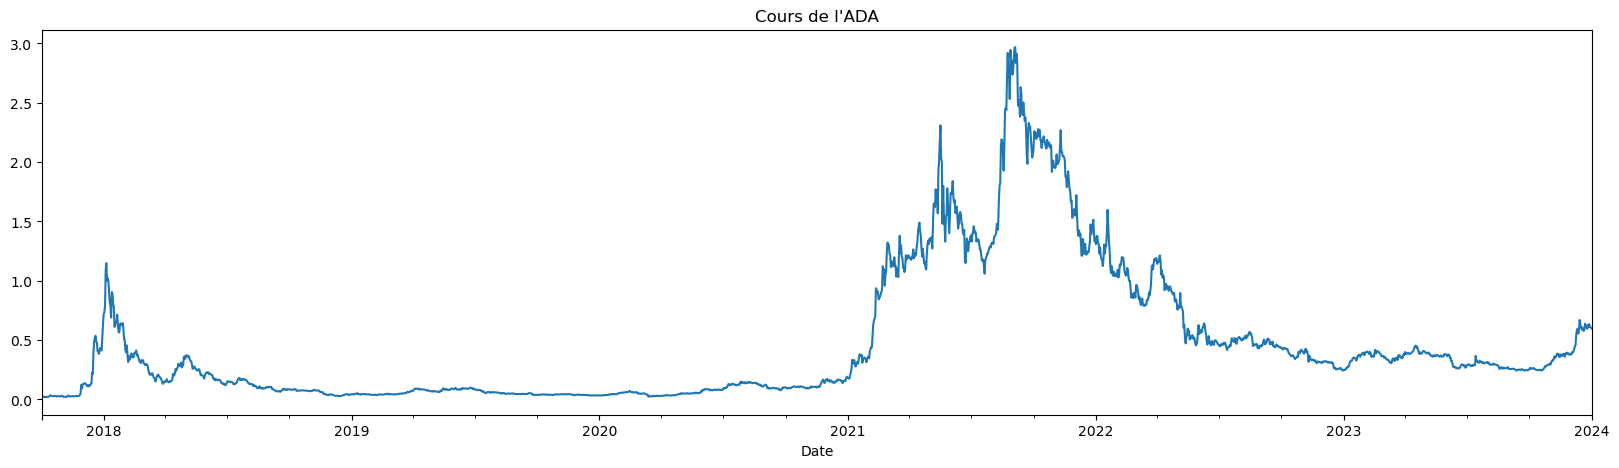

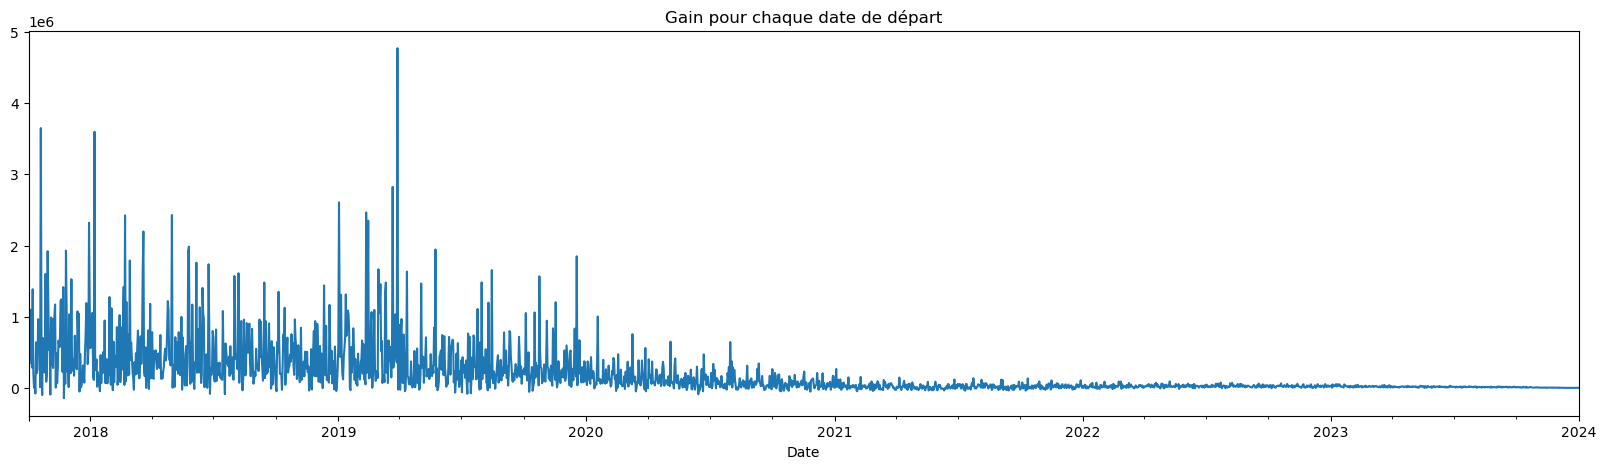

In [40]:
import seaborn as sns
plt.rcParams['figure.figsize'] = [15, 8] # paramètre pour les figures
df.Open.plot(figsize=(20,5), title="Cours de l'ADA")

# new figure
plt.figure()
resultsOnEachDay.gain.plot(figsize=(20,5), title="Gain pour chaque date de départ")



La courbe des prix monte sur l'intervalle de test choisi, donc il fortement possible que vous obteniez parfois des gains élevés en commençant à jouer sur le début de l'intervalle. Plus vous arrivez vers des dates en fin d'intervalle, plus les gains/pertes doivent décroitre vu qu'il y a moins de temps pour réaliser des actions de vente/achat.

La distribution des gains :

<Axes: ylabel='Frequency'>

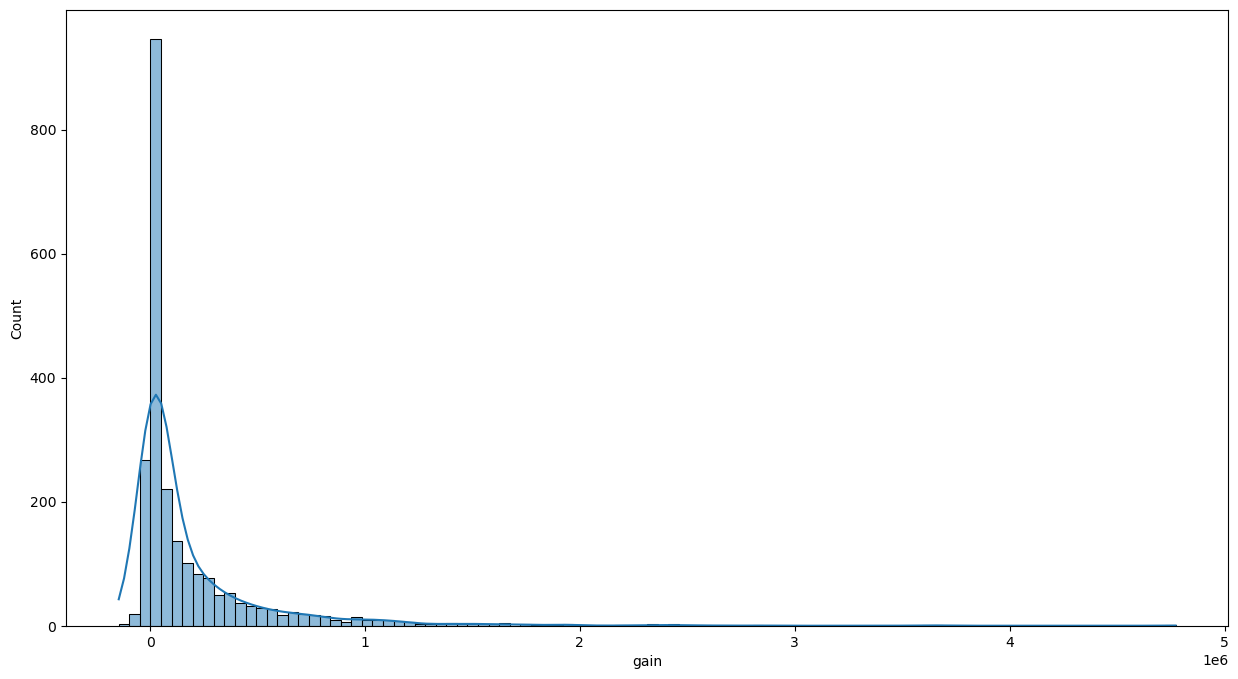

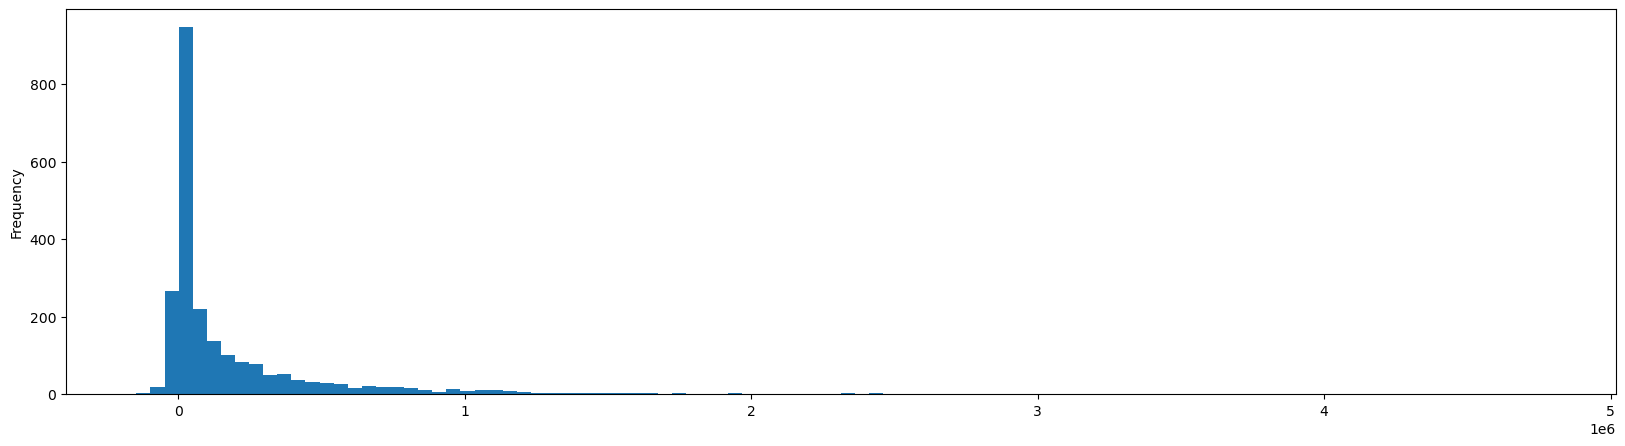

In [41]:

# new figure
plt.figure()
sns.histplot(resultsOnEachDay.gain, kde=True, bins=100)

# new figure
plt.figure()
resultsOnEachDay.gain.plot(kind='hist', bins=100, figsize=(20,5))

In [42]:
resultsOnEachDay.gain.describe()

count    2.283000e+03
mean     1.847246e+05
std      3.542186e+05
min     -1.457873e+05
25%      1.157251e+04
50%      3.915863e+04
75%      2.104281e+05
max      4.772133e+06
Name: gain, dtype: float64

Pour vérifier que notre stratégie fonctionne, il faudrait maintenant voir ce qu'elle donne sur d'autres courbes de prix, ou bien sur des intervalles de chute de prix.

A vos tests.

## Conclusion

Vous êtes maintenant prêt pour le projet. 

Pour la suite, il vous faut maintenant implémenter et tester plusieurs stratégies. Pour ce faire:
- vous avez seulement à ajouter votre stratégie dans le fichier `Strategies.ipynb` (s'il devient trop long, vous pouvez le couper en 2)
- vous utiliserez toujours les notebooks `BaseClasses.ipynb` pour charger les classes de bases `Account`, `Game`, `IStrategy` et `EvalGame`. 
- pour tester vos stratégies, créez un nouveau fichier similaire à `HowToStart.ipynb` ou bien adaptez le si vous voulez comparer plusieurs stratégies entres elles

Commençons par une stratégie simple très populaire : l'effet janvier.
- documentez vous sur l'effet janvier
- implémentez votre stratégie `StrategyJanuaryEffect` **(voir ci-dessous l'aide)**
- adaptez votre stratégie pour pouvoir vendre et acheter à deux mois particulier de l'année **(voir ci-dessous l'aide)**
- appelez cette stratégie `StrategyMonthEffect`
- d'autres stratégies sont disponibles sur le `README.md` du projet !

Si vous voulez creuser le sujet sur des notions d'investissement boursier, la bible semble être ici :
[The intelligent investor](https://www.amazon.fr/Linvestisseur-intelligent-Jason-Zweig/dp/2361170256/ref=asc_df_2361170256/?tag=googshopfr-21&linkCode=df0&hvadid=228777545644&hvpos=&hvnetw=g&hvrand=576117808327018545&hvpone=&hvptwo=&hvqmt=&hvdev=c&hvdvcmdl=&hvlocint=&hvlocphy=9055538&hvtargid=pla-559649545638&psc=1)

Notez que ce livre fait bien la part entre l'investissement et la spéculation, le deuxième étant une tentative de prédiction des prix des valeurs mobilières.

Pour faire de l'investissement, Benjamin Graham définit trois critères :
1. Analyser la valeur mobilière avant son achat
2. votre capital investi est sécurisé (la valeur mobilière ne devrait pas chuter...si les comptes présentés sont justes :) - Enron, crise de 2008...
3. la valeur mobilière générera un retour adéquat

Si ces trois règles ne sont pas respectées alors votre stratégie est de la spéculation et cela revient à jouer au casino, avec des probabilités gagnantes en faveur de votre broker (le broker étant la personne vous permettant d'acheter / vendre les valeurs mobilières). 
